# ZerO: воспроизведение

Здесь можно проверить готовые результаты или заново обучить модели. Объяснение статьи и выводы — в `report.pdf`.

Для чтения кода начните с `initialization.py`, затем `models.py` и `train.py` в папке `hw2/` репозитория. Те же файлы встроены сюда, чтобы ноутбук запускался отдельно в Colab.

[Статья](https://arxiv.org/abs/2110.12661v3) · [Код авторов](https://github.com/jiaweizzhao/ZerO-initialization)

Доля правильных ответов в сохранённых запусках: ZerO по статье: **98.22 ± 0.03%**; ZerO по коду: **98.31 ± 0.04%**; Kaiming: **98.32 ± 0.04%**; Xavier: **98.30 ± 0.05%**. Здесь среднее и разброс трёх повторов. Ниже разберём, что именно повторялось и как читать эти числа.

## 1. Режим запуска

По умолчанию `RUN_TRAINING=False`: анализируем сохраненные измерения без GPU и скачиваний. Для нового обучения поставьте `True` и выберите GPU в Colab: **Runtime → Change runtime type**.

`DOWNLOAD_RESULTS=True` позволит скачать новые журналы. Исходные результаты сохранятся отдельно.

In [1]:
RUN_TRAINING = False
DOWNLOAD_RESULTS = False

## 2. Распакуем файлы

В скрытой ячейке находится архив кода и измерений. Ячейка распакует его во временную папку, чтобы ноутбук запускался самостоятельно.

In [2]:
#@title Распаковать встроенный код и измерения
import base64, io, tempfile, zipfile
from pathlib import Path

PAYLOAD = "..."
WORKSPACE = Path(tempfile.mkdtemp(prefix="zero_hw2_"))
with zipfile.ZipFile(io.BytesIO(base64.b64decode(PAYLOAD))) as bundle:
    bundle.extractall(WORKSPACE)
HW2 = WORKSPACE / "hw2"
print("Код и результаты готовы.")

Код и результаты готовы.


## 3. Библиотеки

Для просмотра результатов нужны NumPy и Matplotlib. Для нового обучения — PyTorch с GPU. Ячейка проверяет окружение; при включенном обучении устанавливает недостающие пакеты через uv.

In [3]:
import importlib.util, shutil, subprocess, sys
from IPython.display import Image, display, HTML

missing = [name for name in ("numpy", "matplotlib") if importlib.util.find_spec(name) is None]
if RUN_TRAINING:
    if shutil.which("uv") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv"], check=True)
    UV = shutil.which("uv")
    if missing:
        subprocess.run([UV, "pip", "install", "--python", sys.executable, *missing], check=True)
    UV_RUN = [UV, "run", "--no-project", "--python", sys.executable, "python"]
else:
    assert not missing, f"Откройте notebook в Colab или заранее установите библиотеки: {missing}. Анализ ничего не скачивает."
import numpy as np
print("NumPy:", np.__version__, "| режим:", "новое обучение" if RUN_TRAINING else "офлайн-анализ")
if RUN_TRAINING:
    import torch, torchvision
    assert torch.cuda.is_available(), "Выберите GPU runtime в Colab; CPU для полного опыта слишком медленный."
    print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

NumPy: 2.5.3 | режим: офлайн-анализ


## 4. Протокол

- **MLP:** полная MNIST, 60 000/10 000 картинок; `784→2048→2048→10`, ReLU, без bias. SGD, шаг 0.1, batch 64, 14 эпох. После эпохи 12 шаг умножается на 0.7; momentum и weight decay равны нулю.
- **Transformer:** 16 патчей 7×7, два блока ширины 64, четыре головы, внутренний слой 256. AdamW, шаг 0.001, batch 128, 10 эпох. Без weight decay и dropout.
- Основные методы повторяются с seed 0, 1, 2; MLP-контроли identity и все нули — с seed 0. Всего **26 запусков**. Seed задает случайность запуска; при одинаковом seed методы получают одинаковый порядок пачек.

В статье и авторском коде различается масштаб Хадамарда: `sqrt(2/M)` и `1/sqrt(M)`. Проверяем оба. Архитектура и 14 эпох MLP взяты из Appendix B; batch и расписание — из авторского notebook, где есть дополнительный слой и 20 эпох.

Условия всех запусков собраны в `results/metadata.json`, точные команды — в `run_colab.py`. Проверяется MNIST; CIFAR-10, ImageNet и WikiText-2 заново не обучаются.

In [4]:
sys.path.insert(0, str(WORKSPACE))
if RUN_TRAINING:
    (HW2 / "results").rename(HW2 / "reference_results")
    subprocess.run(UV_RUN + ["hw2/run_colab.py"], cwd=WORKSPACE, check=True)
else:
    print("Обучение отключено: дальше анализируются сохранённые измерения.")

Обучение отключено: дальше анализируются сохранённые измерения.


## 5. Проверим пример из доказательства

В Appendix A.4 четыре вектора названы независимыми. Но сумма первых двух равна сумме последних двух: ранг равен 3. Ниже это проверяется напрямую.

Для исправленного примера берем входы `(0,±1,±1)` и слой `3→4`: после Хадамарда и ReLU получаем четыре независимых направления. Общий масштаб опущен, поскольку он не меняет ранг. Это исправление конкретного примера, а не опровержение всей статьи.

In [5]:
from hw2 import check_theory
check_theory.main()

Исходные четыре признака, rank=3:
 [[1 0 1 0]
 [0 1 0 1]
 [1 1 0 0]
 [0 0 1 1]]
Исправленные четыре признака, rank=4:
 [[2 0 0 0]
 [0 2 0 0]
 [0 0 2 0]
 [0 0 0 2]]


## 6. Результаты

Точность — доля правильных ответов на тестовых картинках. В таблице указаны среднее и выборочное стандартное отклонение трех запусков, в процентных пунктах. Это наблюдаемый разброс, не доверительный интервал. У контролей один запуск.

На графиках линии показывают среднее, полосы — минимум и максимум.
При чтении CSV проверяем, что все запуски завершены и сводные числа совпадают с последней эпохой.

In [6]:
from contextlib import redirect_stdout
from hw2 import plot_results
with redirect_stdout(io.StringIO()):
    aggregates = plot_results.main()
labels = {
    "zero_paper": "ZerO: статья", "zero_author": "ZerO: код",
    "kaiming": "Kaiming", "xavier": "Xavier", "standard": "Xavier",
    "identity": "Identity", "zero_all": "Все нули",
    "zero_inspired": "ZerO-inspired: статья",
    "zero_inspired_author": "ZerO-inspired: код",
}
from html import escape
rows = []
for group, title in (("paper", "MLP"), ("controls", "MLP: контроли"), ("transformer", "Patch Transformer")):
    for method, values in aggregates[group].items():
        std = "—" if values["accuracy_std_pct"] is None else f'{values["accuracy_std_pct"]:.2f}'
        rows.append(f'<tr><td>{title}</td><td>{escape(labels[method])}</td><td>{values["n"]}</td><td>{values["accuracy_mean_pct"]:.2f}</td><td>{std}</td></tr>')
display(HTML('<table><tr><th>Опыт</th><th>Инициализация</th><th>Запусков</th><th>Test accuracy, %</th><th>Std, п.п.</th></tr>' + ''.join(rows) + '</table>'))

Опыт,Инициализация,Запусков,"Test accuracy, %","Std, п.п."
MLP,ZerO: статья,3,98.22,0.03
MLP,ZerO: код,3,98.31,0.04
MLP,Kaiming,3,98.32,0.04
MLP,Xavier,3,98.30,0.05
MLP: контроли,Identity,1,98.22,—
MLP: контроли,Все нули,1,9.80,—
Patch Transformer,Xavier,3,97.59,0.59
Patch Transformer,Identity,3,96.97,0.15
Patch Transformer,ZerO-inspired: статья,3,97.19,0.11
Patch Transformer,ZerO-inspired: код,3,97.67,0.27


## 7. Точность MLP

Слева — доля правильных ответов, справа — ошибка обучения. Авторы сообщают в Appendix B точность выше 98%; сравним с нашими измерениями. Настройки опыта указаны выше.

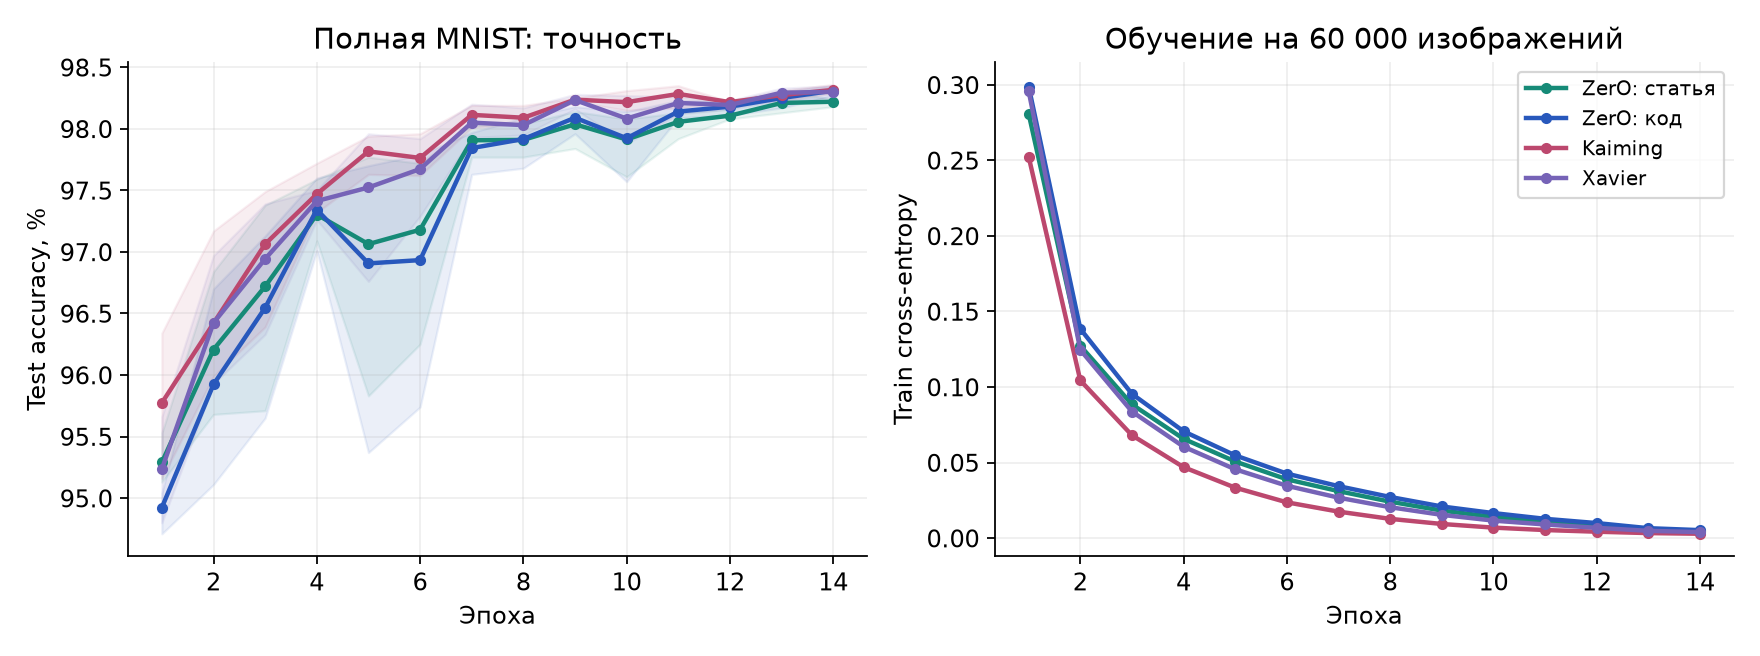

In [7]:
display(Image(filename=str(HW2 / "results/figures/mnist_learning.png")))

## 8. Ранг и ширина

Измеряем ранг **поправки `W₂−I`**: сама единичная матрица уже полного ранга. Ранг признаков оценивается по 1024 картинкам и не может превысить 1024.

Численный ранг отбрасывает направления ниже выбранного порога. Первый график использует `10⁻⁴`, второй показывает чувствительность к порогу. Разложение SVD считается в float64. `stable_rank` в `rank.csv` — отдельная метрика `sum(σ²)/σ_max²`.

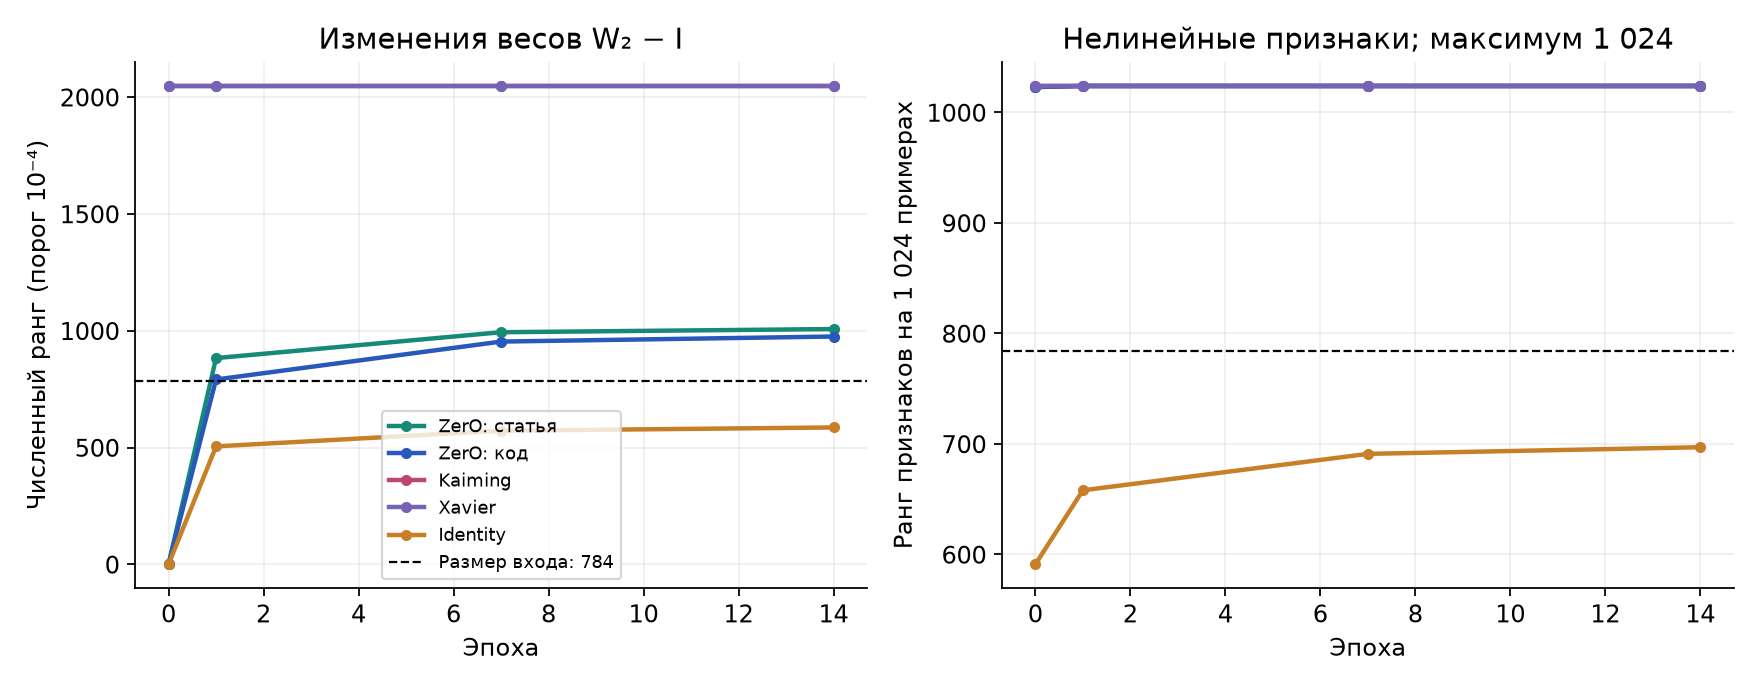

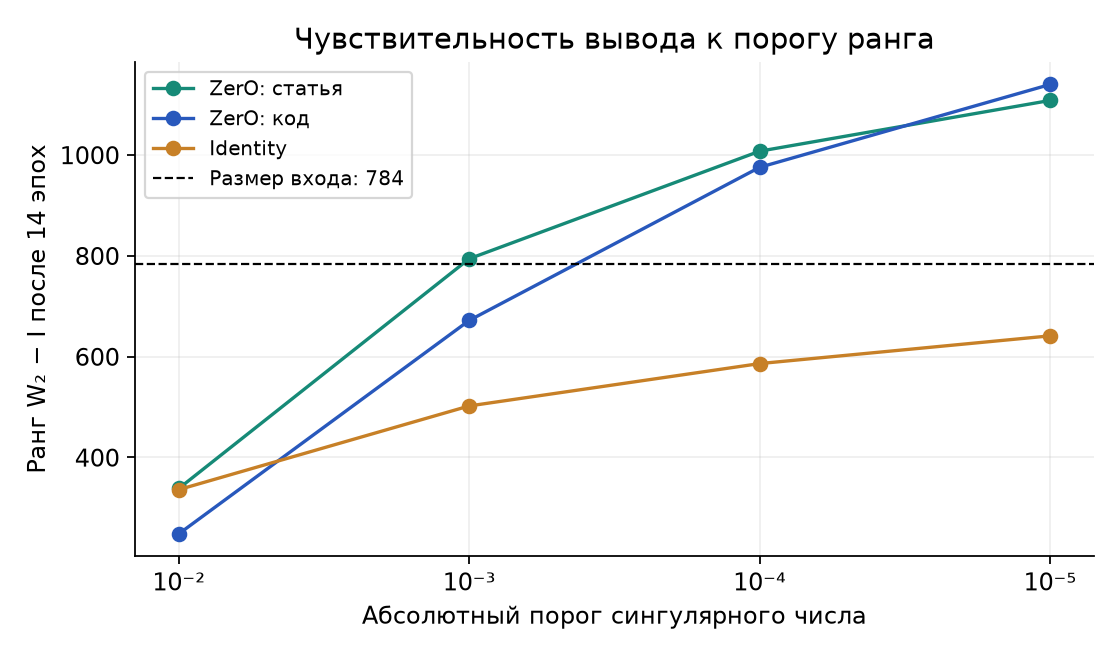

In [8]:
display(Image(filename=str(HW2 / "results/figures/mnist_rank.png")))
display(Image(filename=str(HW2 / "results/figures/rank_tolerance.png")))

## 9. Transformer на цифрах

Патчи изображения обмениваются информацией через attention. Матрицы Q, K и V дают векторы запросов, ключей и передаваемого содержимого.

В ZerO-inspired матрица Q и выходная проекция attention начинаются с identity; K и V — с нулей. Остальные Linear используют Algorithm 1, позиции патчей фиксированы. Для обычного старта все Linear явно получают Xavier.

На старте внимание равномерное, а выход attention нулевой. Обходной путь позволяет передавать признаки дальше. В наших запусках сначала меняется V, затем появляются градиенты K и Q.

Transformer уже есть в статье на WikiText-2. Наше дополнение — задача на патчах MNIST и проверка первых шагов обучения.

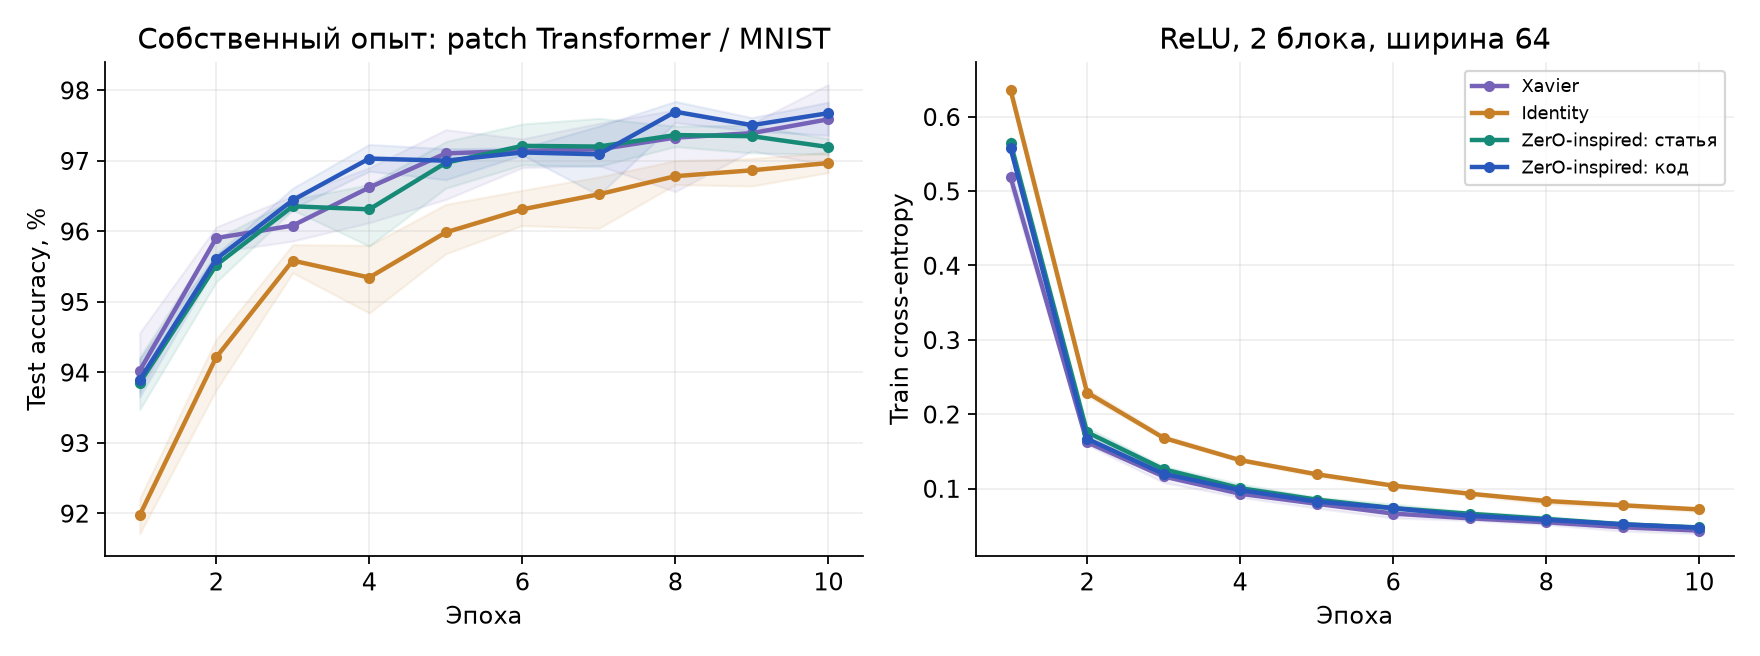

In [9]:
display(Image(filename=str(HW2 / "results/figures/transformer_learning.png")))

## 10. Выводы

Смотрим на точность вместе с диагностикой: ограниченный ранг identity не помешал хорошо распознавать цифры. Трех повторов мало для уверенного вывода о превосходстве метода.

Время в CSV включает оценку качества и диагностику. Скорость работы обученной модели и сжатие весов здесь не измерялись. После нового обучения последняя ячейка сохранит ZIP журналов.

In [10]:
paper = aggregates["paper"]
identity = aggregates["controls"]["identity"]
rank = aggregates["final_rank"]
mean_values = [values["accuracy_mean_pct"] for values in paper.values()]
zero_rank = rank["zero_paper"]["rank_tol_0.0001"]["mean"]
author_rank = rank["zero_author"]["rank_tol_0.0001"]["mean"]
identity_rank = rank["identity"]["rank_tol_0.0001"]["mean"]
transformer = aggregates["transformer"]
zero_transformer = transformer["zero_inspired_author"]
baseline = transformer["standard"]
display(HTML(
    f'<p><b>MLP:</b> средняя test accuracy четырёх основных методов: {min(mean_values):.2f}–{max(mean_values):.2f}%. '
    f'Partial identity получила {identity["accuracy_mean_pct"]:.2f}% в одном запуске при ранге W₂−I {identity_rank:.0f} ≤ 784. '
    'Ограничение ранга само по себе не доказывает низкую точность на MNIST.</p>'
    f'<p><b>Ранг при пороге 10⁻⁴:</b> ZerO по статье {zero_rank:.1f}, ZerO по коду {author_rank:.1f} — оба выше 784. '
    'Изменение порога влияет на этот вывод; это видно на отдельном графике.</p>'
    f'<p><b>Transformer:</b> ZerO-inspired с нормировкой кода: {zero_transformer["accuracy_mean_pct"]:.2f} ± '
    f'{zero_transformer["accuracy_std_pct"]:.2f}%; Xavier: {baseline["accuracy_mean_pct"]:.2f} ± '
    f'{baseline["accuracy_std_pct"]:.2f}%. Это среднее ± sample std по трём seed, без утверждения универсального превосходства.</p>'
))

In [11]:
if RUN_TRAINING:
    export_path = shutil.make_archive(str(WORKSPACE / "zero_hw2_results"), "zip", HW2 / "results")
    print("Архив новых результатов:", export_path)
    if DOWNLOAD_RESULTS:
        try:
            from google.colab import files
            files.download(export_path)
        except ImportError:
            print("Вне Colab скачайте ZIP по напечатанному пути.")